# Xem kết quả train – CERT r4.2
Chọn kernel **Python (soc-ueba)** ở góc trên bên phải, rồi `Run All`.

In [1]:
import sys, json, pandas as pd, joblib
sys.path.insert(0, '../src')
from IPython.display import Image, display
from config import PROCESSED_DIR, REPORTS_DIR, MODELS_DIR
pd.set_option('display.max_columns', 40)

## 1. Quá trình train Autoencoder
Loss giảm rồi phẳng, train ≈ validation → học được, không học vẹt (overfit).

,epoch,train_loss,val_loss
25,25,0.378570,0.380567
26,26,0.377197,0.378686
27,27,0.375807,0.377661
28,28,0.374924,0.376474
29,29,0.373654,0.374996


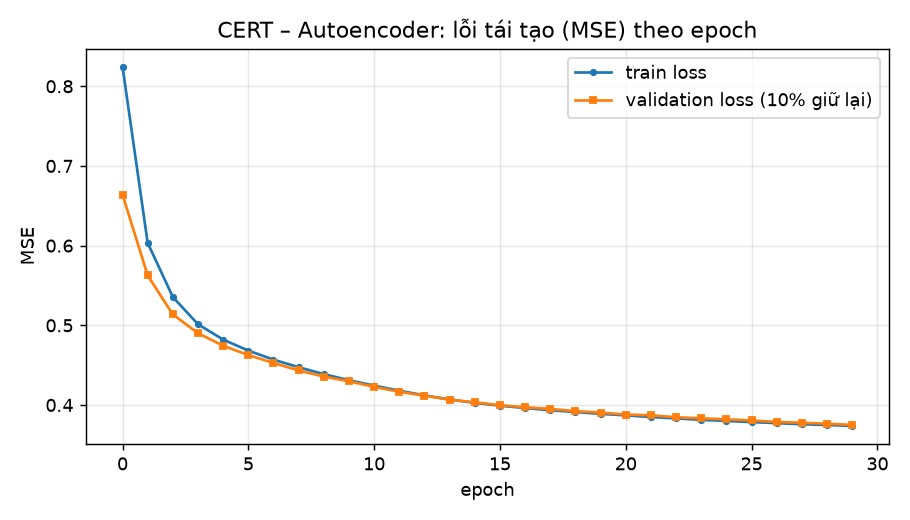

In [2]:
hist = pd.DataFrame(joblib.load(MODELS_DIR / 'cert_anomaly.joblib')['ae_loss_history'])
display(hist.tail())
display(Image(REPORTS_DIR / 'cert_train_loss.png'))

## 2. So sánh phương án (3 seed) → chọn trên validation → metric trên test
Feature URL không còn lấy domain từ nhãn `answers/` (bản cũ bị rò nhãn); thay bằng độ hiếm domain + danh mục URL. `day+win` = thêm tổng 7/30 ngày.

In [3]:
exp = pd.read_csv(REPORTS_DIR / 'cert_experiments.csv')
display(exp[['features','split','method','roc_auc','pr_auc','pr_auc_std','insiders@2/day','insiders@5/day','by_scenario@5/day']].round(3))
print(json.load(open(REPORTS_DIR / 'cert_model_selection.json')))
pd.read_csv(REPORTS_DIR / 'cert_test_metrics.csv', index_col=0).round(3)

,features,split,method,roc_auc,pr_auc,pr_auc_std,insiders@2/day,insiders@5/day,by_scenario@5/day
0,day,val,stat,0.861,0.029,0.000,3.000,6.000,"{1: '3/8', 2: '2/13', 3: '1/3'}"
1,day,val,ecod,0.838,0.046,0.000,9.000,9.000,"{1: '5/8', 2: '1/13', 3: '3/3'}"
2,day,val,iforest,0.905,0.090,0.002,10.667,14.000,"{1: '8/8', 2: '4/13', 3: '3/3'}"
3,day,val,ae,0.912,0.119,0.003,16.000,19.333,"{1: '8/8', 2: '9/13', 3: '3/3'}"
4,day,val,ens_mean,0.921,0.086,0.002,13.333,17.000,"{1: '8/8', 2: '6/13', 3: '3/3'}"
5,day,val,ens_ecod_ae,0.898,0.095,0.003,12.000,12.667,"{1: '8/8', 2: '2/13', 3: '3/3'}"
6,day,val,ens_all,0.910,0.078,0.001,11.667,14.000,"{1: '8/8', 2: '3/13', 3: '3/3'}"
7,day,val,iforest_sm7,0.920,0.062,0.003,1.000,1.000,"{1: '0/8', 2: '1/13', 3: '0/3'}"
8,day,val,ae_sm7,0.939,0.103,0.010,4.000,6.333,"{1: '0/8', 2: '6/13', 3: '0/3'}"
9,day,val,ens_mean_sm7,0.936,0.059,0.003,0.333,1.333,"{1: '0/8', 2: '2/13', 3: '0/3'}"


{'validation_pr_auc': {'stat_score': 0.026283772765901197, 'iforest_score': 0.1472780276437003, 'ae_score': 0.11575021230652945, 'ensemble_score': 0.09017205707006964}, 'selected': 'iforest_score'}


,roc_auc,pr_auc,precision@100,recall@100,recall@1000,alerts,recall_at_threshold,fpr_at_threshold
stat_score,0.856,0.014,0.00,0.000,0.010,4527.0,0.045,0.028
iforest_score,0.950,0.058,0.20,0.032,0.103,914.0,0.101,0.005
ae_score,0.946,0.084,0.27,0.043,0.154,750.0,0.131,0.004
ensemble_score,0.933,0.041,0.14,0.022,0.048,986.0,0.048,0.006


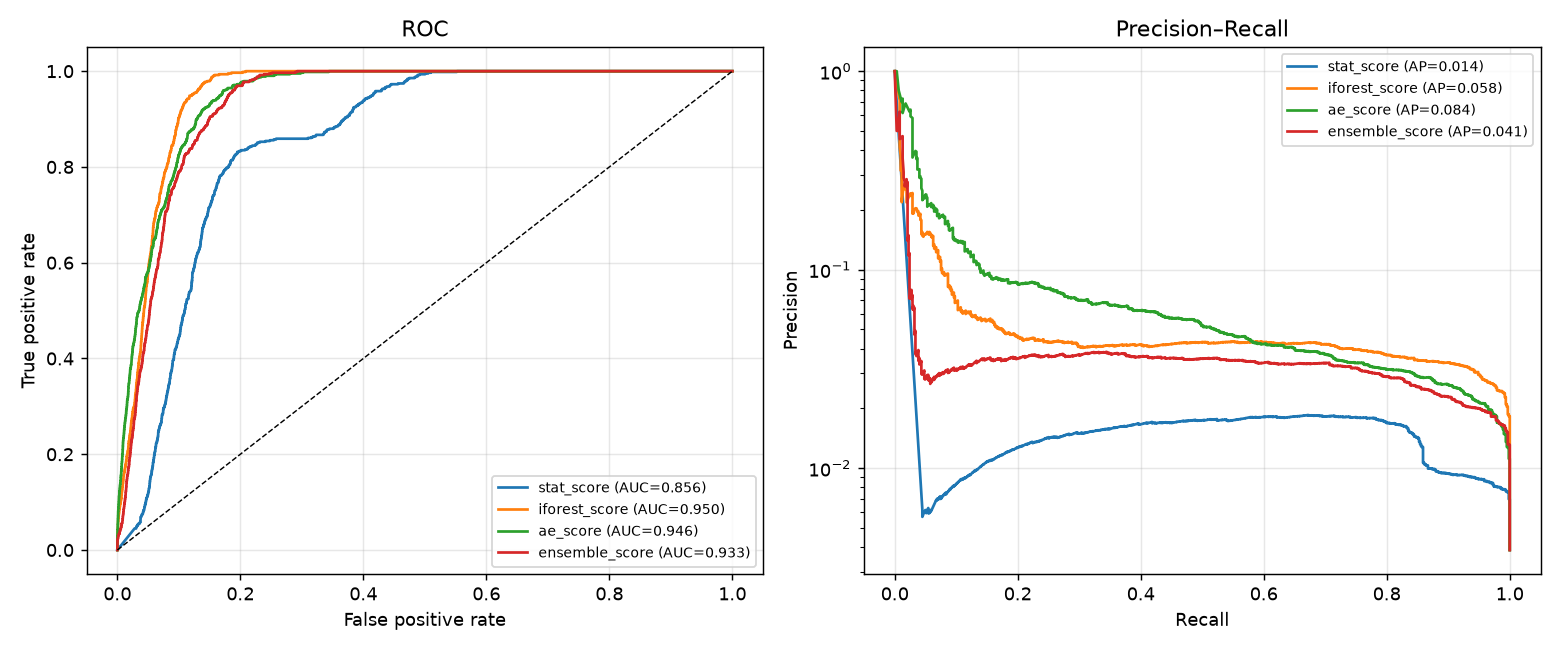

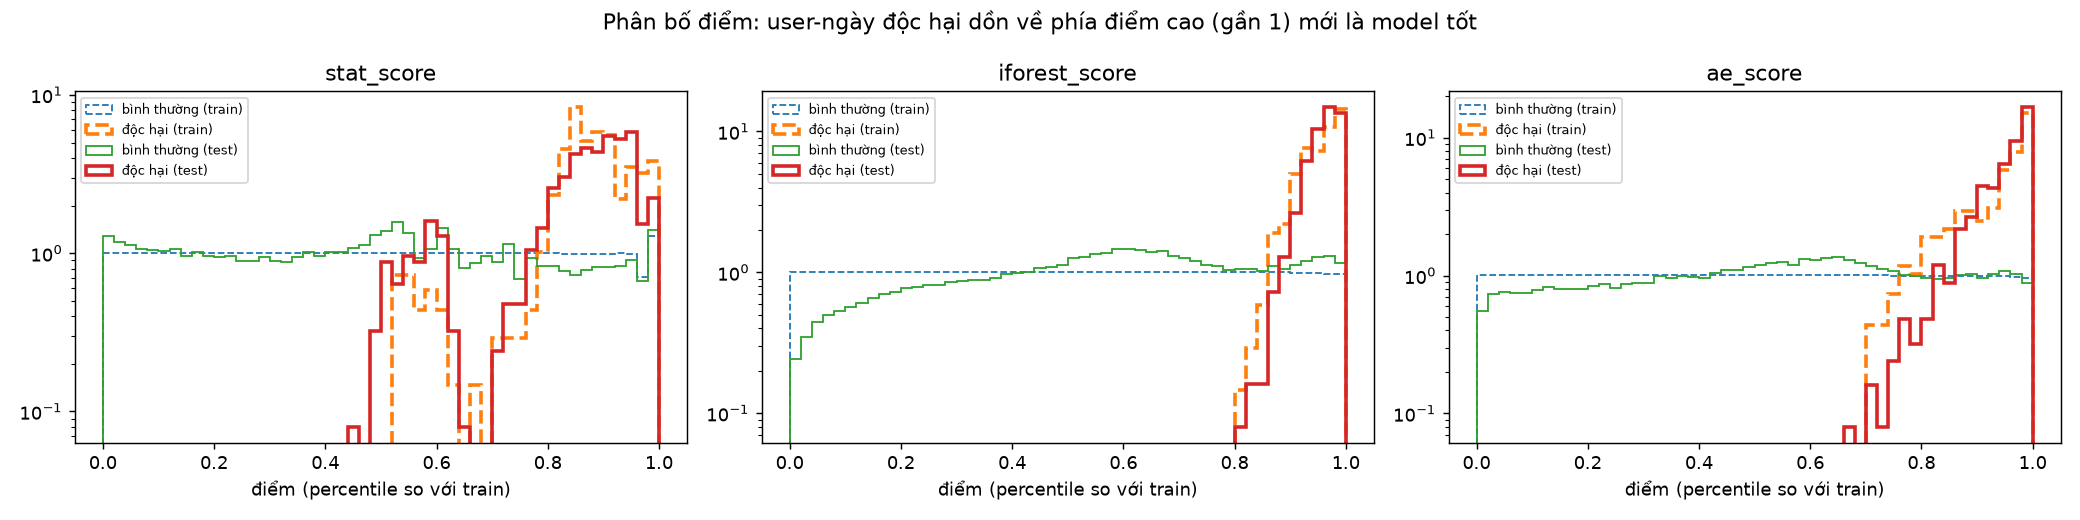

In [4]:
display(Image(REPORTS_DIR / 'cert_test_roc_pr.png'))
display(Image(REPORTS_DIR / 'cert_score_dist.png'))

## 3. Bắt được bao nhiêu insider?

In [5]:
json.load(open(REPORTS_DIR / 'cert_summary.json'))['user_level']

{'0.99': {'alerts': 1843,
  'alerts_per_day': 7.12,
  'insiders_caught': 41,
  'insiders_total': 52,
  'by_scenario': {'1': '22/22', '2': '14/25', '3': '5/5'}},
 '0.995': {'alerts': 914,
  'alerts_per_day': 3.53,
  'insiders_caught': 31,
  'insiders_total': 52,
  'by_scenario': {'1': '20/22', '2': '6/25', '3': '5/5'}},
 '0.999': {'alerts': 249,
  'alerts_per_day': 0.96,
  'insiders_caught': 23,
  'insiders_total': 52,
  'by_scenario': {'1': '17/22', '2': '1/25', '3': '5/5'}},
 'top2/day': {'alerts': 518,
  'insiders_caught': 27,
  'insiders_total': 52,
  'by_scenario': {'1': '18/22', '2': '4/25', '3': '5/5'}},
 'top5/day': {'alerts': 1294,
  'insiders_caught': 35,
  'insiders_total': 52,
  'by_scenario': {'1': '21/22', '2': '9/25', '3': '5/5'}}}

## 4. Bảng điểm – 20 user-ngày bất thường nhất trong tập test

In [6]:
s = pd.read_parquet(PROCESSED_DIR / 'cert_scores.parquet')
test = s[s.split == 'test']
test.sort_values('alert_score', ascending=False)[['user','date','role','alert_score','ae_score','iforest_score','stat_score','is_malicious','scenario','top_reasons','usb_n','w30_usb_n','http_rare_max','http_n_rare','http_job']].head(20)

,user,date,role,alert_score,ae_score,iforest_score,stat_score,is_malicious,scenario,top_reasons,usb_n,w30_usb_n,http_rare_max,http_n_rare,http_job
224501,MSO0222,2010-12-09,ITAdmin,0.999987,0.999980,0.999987,1.000000,True,3.0,"[file_exe, http_n_rare, usb_offhours]",2.0,2.0,6.215608,3.0,9.0
80031,DCH0843,2011-01-29,ProductionLineWorker,0.999987,0.999980,0.999987,1.000000,False,NaN,"[usb_offhours, logon_weekend, w30_usb_offhours]",5.0,11.0,1.073944,0.0,0.0
209262,MCF0600,2010-09-20,ProductionLineWorker,0.999987,0.999872,0.999987,1.000000,True,1.0,"[usb_offhours, file_zip, file_n]",10.0,10.0,4.423848,0.0,0.0
167584,JLM0364,2011-04-28,ITAdmin,0.999987,0.999993,0.999987,1.000000,True,3.0,"[file_exe, http_n_rare, usb_offhours]",2.0,2.0,5.810143,6.0,2.0
13453,AJR0932,2010-09-10,ComputerProgrammer,0.999987,0.999764,0.999987,1.000000,True,1.0,"[usb_offhours, http_n_rare, file_n]",9.0,9.0,4.711530,1.0,0.0
203456,LQC0479,2010-09-14,Salesman,0.999987,0.999872,0.999987,1.000000,True,1.0,"[usb_offhours, file_zip, file_n]",7.0,7.0,4.510859,0.0,13.0
209266,MCF0600,2010-09-24,ProductionLineWorker,0.999987,0.999818,0.999987,1.000000,False,NaN,"[usb_offhours, file_exe, file_zip]",8.0,20.0,1.556897,0.0,0.0
112442,FTM0406,2010-11-22,SystemsEngineer,0.999980,0.999253,0.999980,1.000000,False,NaN,"[usb_offhours, file_n, file_zip]",8.0,8.0,2.172556,0.0,5.0
206995,MAR0955,2011-02-05,ProductionLineWorker,0.999980,0.999980,0.999980,1.000000,False,NaN,"[usb_offhours, logon_weekend, file_n]",5.0,5.0,1.497109,0.0,0.0
207003,MAR0955,2011-02-16,ProductionLineWorker,0.999973,0.999192,0.999973,1.000000,False,NaN,"[usb_offhours, file_zip, w30_usb_offhours]",5.0,21.0,1.858899,0.0,0.0


## 5. Xem dòng thời gian của 1 user bất kỳ (đổi tên user ở dưới)

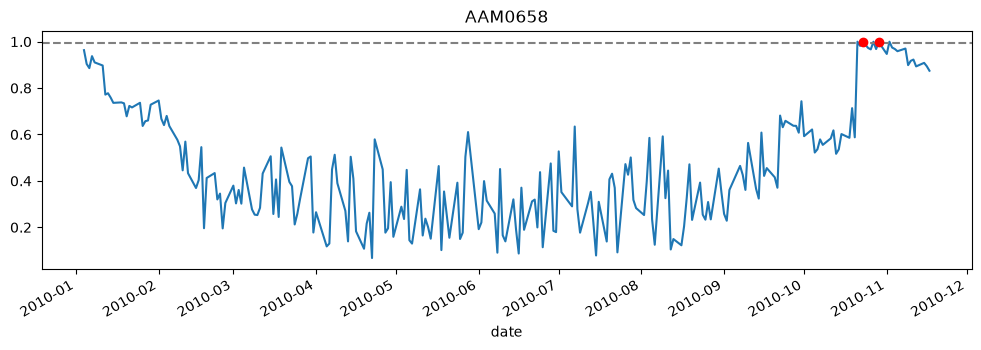

In [7]:
import matplotlib.pyplot as plt
USER = test.loc[test.is_malicious, 'user'].iloc[0]   # vd: 'PPF0435'
u = s[s.user == USER].sort_values('date')
ax = u.plot(x='date', y='alert_score', figsize=(12, 3.5), legend=False, title=USER)
ax.scatter(u.loc[u.is_malicious, 'date'], u.loc[u.is_malicious, 'alert_score'], color='red', zorder=3)
ax.axhline(0.995, ls='--', color='gray'); plt.show()

## 6. Feature nào quyết định & dữ liệu ban đầu (EDA)

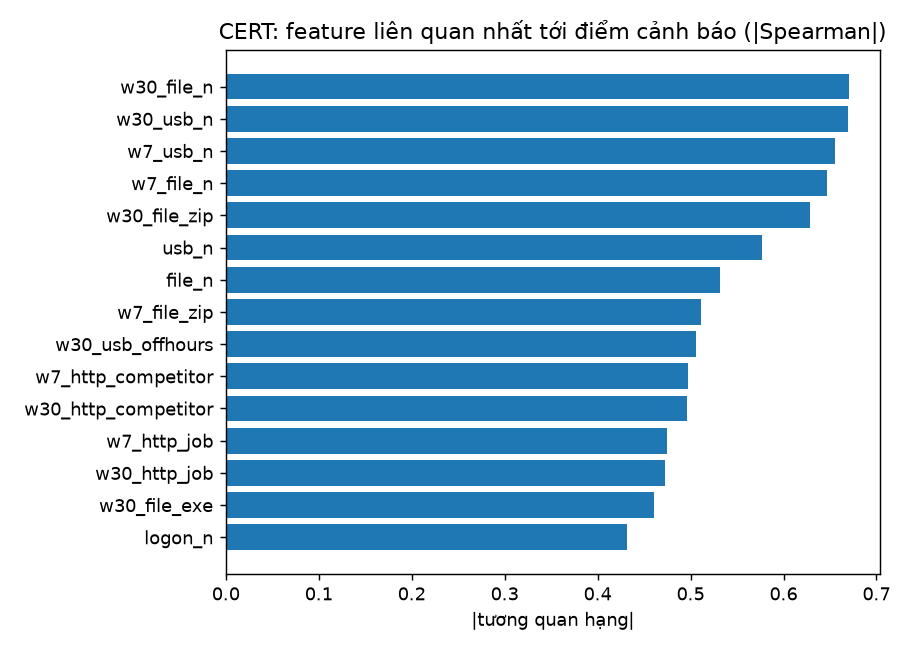

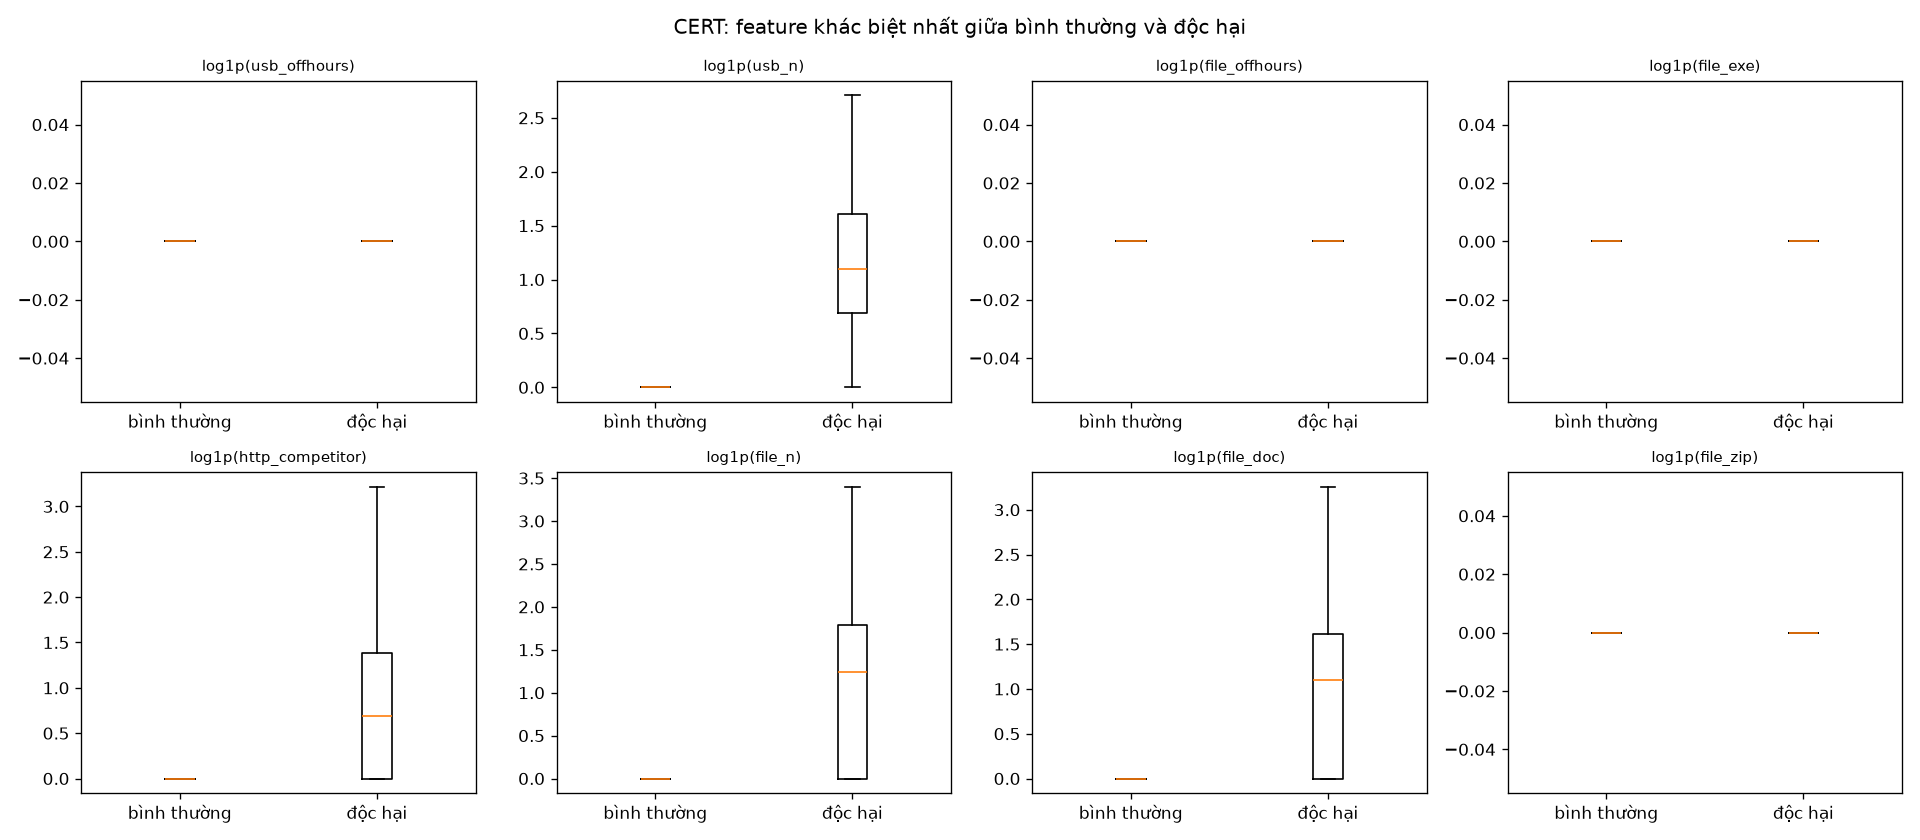

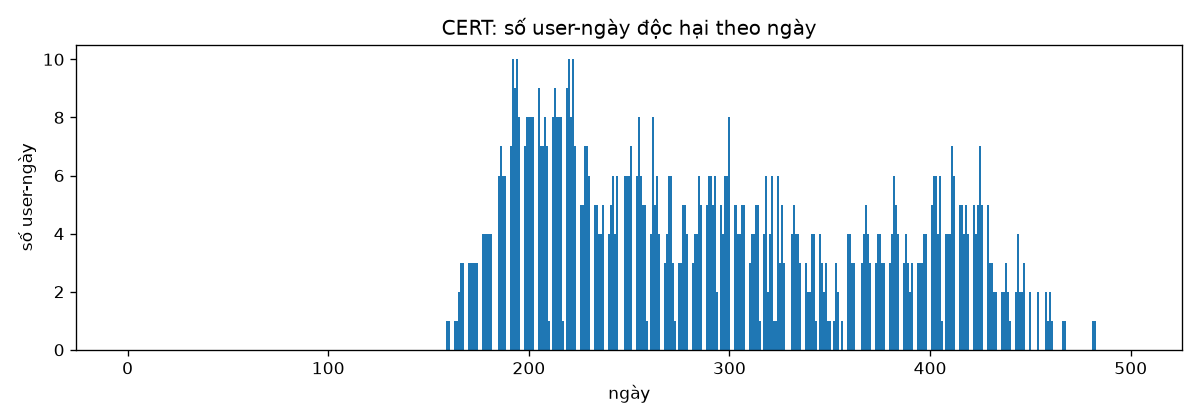

In [8]:
for f in ['cert_feature_importance.png', 'cert_eda_feature_compare.png', 'cert_eda_labels_over_time.png']:
    display(Image(REPORTS_DIR / f))

## 7. Một cảnh báo xuất cho Người B (đúng schema)

In [9]:
alerts = json.load(open(REPORTS_DIR / 'alerts_cert.json', encoding='utf-8'))
print(len(alerts), 'cảnh báo'); alerts[0]

500 cảnh báo


{'alert_id': 'cert-20101209-00001',
 'timestamp': '2010-12-09T00:00:00Z',
 'user': 'MSO0222',
 'src_host': None,
 'dst_host': None,
 'source': 'ml',
 'rule_id': None,
 'anomaly_score': 1.0,
 'is_human_prob': None,
 'severity': 'critical',
 'mitre': {'tactic': 'Exfiltration',
  'technique_id': 'T1052.001',
  'technique_name': 'Exfiltration over Physical Medium: Exfiltration over USB'},
 'features': {'logon_offhours': 7.0,
  'logon_weekend': 0.0,
  'logon_pcs': 6.0,
  'usb_n': 2.0,
  'usb_offhours': 1.0,
  'file_n': 1.0,
  'file_exe': 1.0,
  'file_zip': 0.0,
  'email_ext_rcpt': 7.0,
  'email_attach': 0.0,
  'http_job': 9.0,
  'http_competitor': 7.0,
  'http_rare_max': 6.216,
  'http_n_rare': 3.0,
  'http_n_new_domain': 3.0,
  'top_reasons': ['file_exe', 'http_n_rare', 'usb_offhours'],
  'role': 'ITAdmin',
  'dataset': 'CERT r4.2',
  'ground_truth_insider': True},
 'agent_analysis': None}